<a href="https://colab.research.google.com/github/ragnarlotbrak/Road-Sign-Recognition-System-for-Driver-Assistance-Based-on-YOLO/blob/DIP-8-dataset-validation-notebook/dataset_check_and_baseline_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Road Sign Recognition: проверка датасета и baseline YOLOv8
Runtime: Runtime > Change runtime type > T4 GPU. Датасет: zip в формате YOLO (data.yaml, train/val/test с images и labels).

In [2]:
!pip -q install ultralytics
from google.colab import drive
drive.mount('/content/drive')


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 7.6 MB/s eta 0:00:00
Mounted at /content/drive


In [1]:
# 1. Загрузка датасета по ссылке Google Drive
DATASET_URL = 'https://drive.google.com/drive/folders/1HLAWxdLGdXSkmfgzKq2AbTzR2fnwHCEC?usp=drive_link'
DATA_DIR = '/content/dataset'

import os, glob, zipfile, yaml, gdown
os.makedirs(DATA_DIR, exist_ok=True)

if not glob.glob(f'{DATA_DIR}/**/data.yaml', recursive=True):
    if '/folders/' in DATASET_URL:
        gdown.download_folder(url=DATASET_URL, output=DATA_DIR, quiet=True, remaining_ok=True)
    else:
        gdown.download(url=DATASET_URL, output=f'{DATA_DIR}/dataset.zip', fuzzy=True)
    for z in glob.glob(f'{DATA_DIR}/**/*.zip', recursive=True):
        with zipfile.ZipFile(z) as f:
            f.extractall(DATA_DIR)

yaml_path = glob.glob(f'{DATA_DIR}/**/data.yaml', recursive=True)[0]
ROOT = os.path.dirname(yaml_path)
cfg = yaml.safe_load(open(yaml_path))
names = cfg['names']
if isinstance(names, dict):
    names = [names[k] for k in sorted(names)]
NC = len(names)
print('Корень датасета:', ROOT)
print('Классов:', NC)
print(names)


Корень датасета: /content/dataset/road_signs_yolo_aug
Классов: 20
['Danger Ahead', 'Give Way', 'Left Sharp Curve', 'No Entry', 'No Over Taking', 'No Over Taking Trucks', 'Right Sharp Curve', 'Speed Limit 100', 'Speed Limit 110', 'Speed Limit 120', 'Speed Limit 20', 'Speed Limit 30', 'Speed Limit 40', 'Speed Limit 50', 'Speed Limit 60', 'Speed Limit 70', 'Speed Limit 80', 'Speed Limit 90', 'Stop', 'Turn Right']


In [3]:
# 2. Dataset test
from pathlib import Path
from PIL import Image
import hashlib, collections

IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

def find_splits(root):
    res = {}
    for s in ['train', 'val', 'valid', 'test']:
        a = (Path(root) / s / 'images', Path(root) / s / 'labels')
        b = (Path(root) / 'images' / s, Path(root) / 'labels' / s)
        if a[0].exists():
            res[s] = a
        elif b[0].exists():
            res[s] = b
    return res

splits = find_splits(ROOT)
print('Найдены части:', list(splits))

errors = []
background = collections.Counter()
counts = {s: collections.Counter() for s in splits}
n_images = {}
hashes = {}

for s, (imgd, lbld) in splits.items():
    imgs = [p for p in imgd.iterdir() if p.suffix.lower() in IMG_EXT]
    lbls = {p.stem: p for p in lbld.glob('*.txt')}
    n_images[s] = len(imgs)
    for p in imgs:
        try:
            Image.open(p).verify()
        except Exception:
            errors.append(f'{s}: битое изображение {p.name}')
            continue
        hashes.setdefault(hashlib.md5(p.read_bytes()).hexdigest(), []).append((s, p.name))
        if p.stem not in lbls:
            errors.append(f'{s}: нет файла разметки для {p.name}')
            continue
        lines = [l for l in lbls[p.stem].read_text().splitlines() if l.strip()]
        if not lines:
            background[s] += 1
        for i, line in enumerate(lines, 1):
            parts = line.split()
            if len(parts) != 5:
                errors.append(f'{s}: {p.stem}.txt строка {i}: нужно 5 значений, а не {len(parts)}')
                continue
            try:
                c = int(parts[0])
                x, y, w, h = map(float, parts[1:])
            except ValueError:
                errors.append(f'{s}: {p.stem}.txt строка {i}: нечисловые значения')
                continue
            if not 0 <= c < NC:
                errors.append(f'{s}: {p.stem}.txt строка {i}: класс {c} вне диапазона 0..{NC-1}')
            if not all(0 <= v <= 1 for v in (x, y, w, h)):
                errors.append(f'{s}: {p.stem}.txt строка {i}: координаты не в диапазоне 0..1')
            if w <= 0 or h <= 0:
                errors.append(f'{s}: {p.stem}.txt строка {i}: нулевая ширина или высота')
            counts[s][c] += 1
    for stem in set(lbls) - {p.stem for p in imgs}:
        errors.append(f'{s}: разметка {stem}.txt без изображения')

# утечка данных
for h, items in hashes.items():
    if len({s for s, _ in items}) > 1:
        errors.append(f'Утечка train/val/test: {items}')

# в каждой части должны быть примеры каждого класса
for s in splits:
    missing = [names[c] for c in range(NC) if counts[s][c] == 0]
    if missing:
        print(f'ПРЕДУПРЕЖДЕНИЕ: в {s} нет примеров классов: {missing}')

print('\nИзображений по частям:', n_images)
print('Фоновых (без объектов):', dict(background))
print('Найдено ошибок:', len(errors))
for e in errors[:30]:
    print(' ', e)
assert not errors, 'Датасет содержит ошибки, исправьте их перед обучением'
print('Все проверки датасета пройдены')


Найдены части: ['train', 'valid', 'test']

Изображений по частям: {'train': 6652, 'valid': 717, 'test': 727}
Фоновых (без объектов): {}
Найдено ошибок: 0
Все проверки датасета пройдены


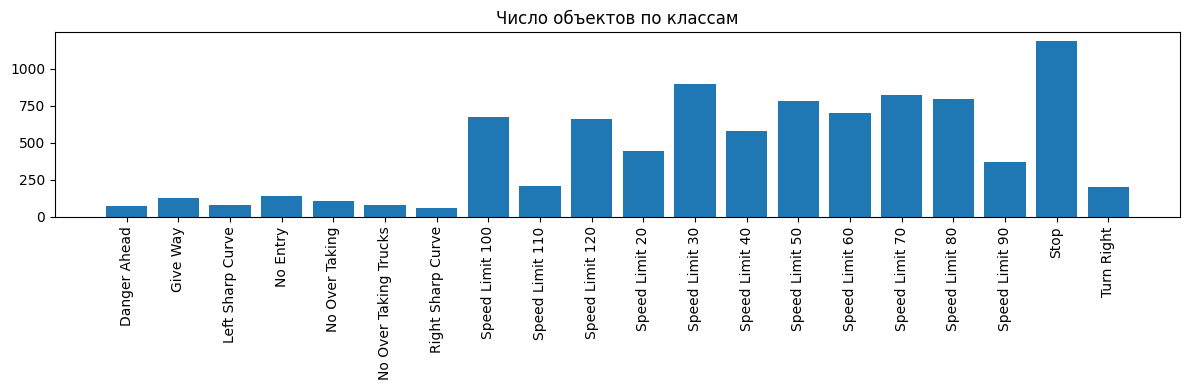

In [4]:
# 3. Распределение классов
import matplotlib.pyplot as plt
total = collections.Counter()
for s in counts:
    total.update(counts[s])
plt.figure(figsize=(12, 4))
plt.bar([names[c] for c in range(NC)], [total[c] for c in range(NC)])
plt.xticks(rotation=90)
plt.title('Число объектов по классам')
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150)
plt.show()


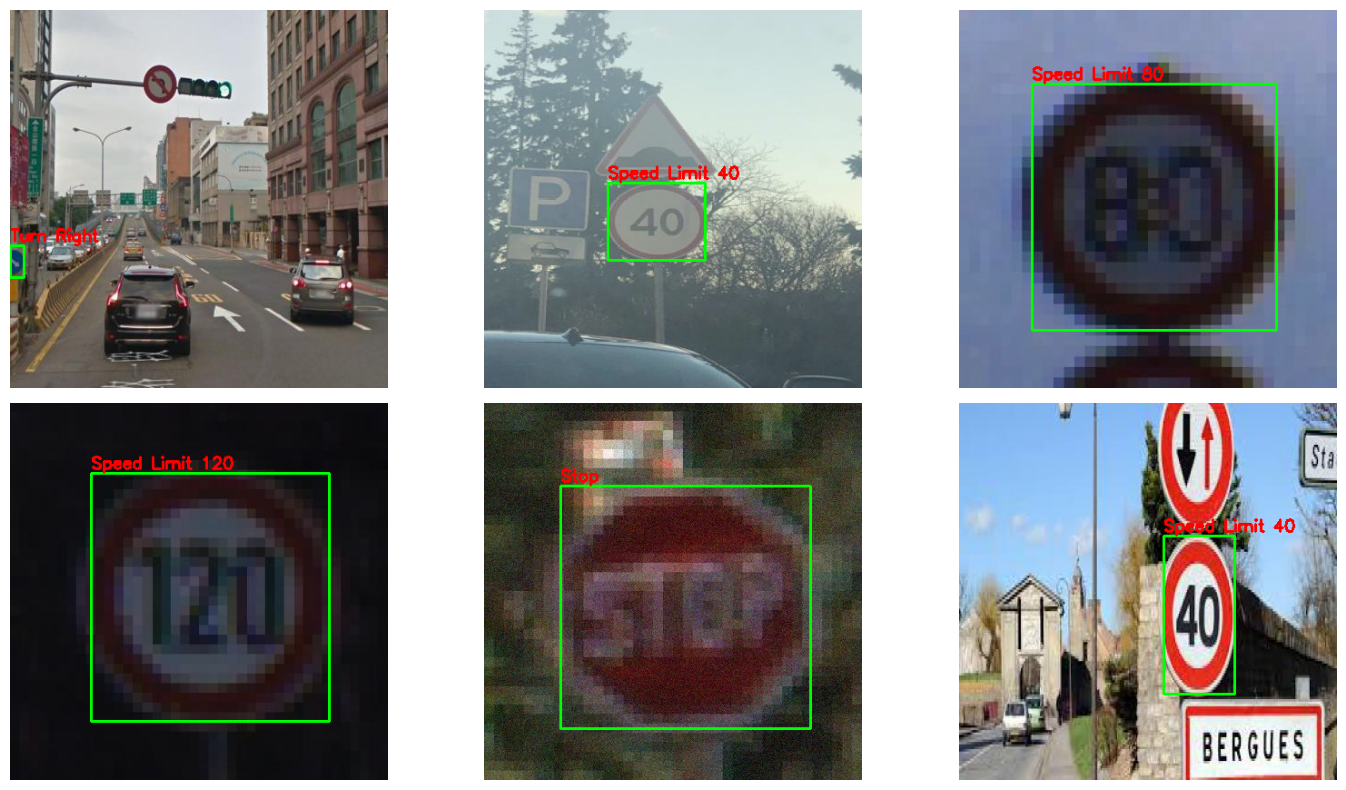

In [5]:
# 4. визуальна проверка
import random, cv2
s0 = 'train' if 'train' in splits else list(splits)[0]
imgd, lbld = splits[s0]
sample = random.sample([p for p in imgd.iterdir() if p.suffix.lower() in IMG_EXT], 6)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, p in zip(axes.ravel(), sample):
    img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    lf = lbld / (p.stem + '.txt')
    if lf.exists():
        for line in lf.read_text().splitlines():
            if not line.strip():
                continue
            c, x, y, w, h = line.split()
            x, y, w, h = float(x) * W, float(y) * H, float(w) * W, float(h) * H
            p1, p2 = (int(x - w / 2), int(y - h / 2)), (int(x + w / 2), int(y + h / 2))
            cv2.rectangle(img, p1, p2, (0, 255, 0), 2)
            cv2.putText(img, names[int(c)], (p1[0], max(p1[1] - 5, 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
    ax.imshow(img)
    ax.axis('off')
plt.tight_layout()
plt.savefig('label_check.png', dpi=120)
plt.show()


In [6]:
# 5. Свой data.yaml с абсолютными путями
val_key = 'val' if 'val' in splits else 'valid'
new_cfg = {'path': str(ROOT), 'train': str(splits['train'][0]), 'val': str(splits[val_key][0]), 'names': names}
if 'test' in splits:
    new_cfg['test'] = str(splits['test'][0])
DATA_YAML = '/content/data_fixed.yaml'
yaml.safe_dump(new_cfg, open(DATA_YAML, 'w'), allow_unicode=True)
print(open(DATA_YAML).read())


names:
- Danger Ahead
- Give Way
- Left Sharp Curve
- No Entry
- No Over Taking
- No Over Taking Trucks
- Right Sharp Curve
- Speed Limit 100
- Speed Limit 110
- Speed Limit 120
- Speed Limit 20
- Speed Limit 30
- Speed Limit 40
- Speed Limit 50
- Speed Limit 60
- Speed Limit 70
- Speed Limit 80
- Speed Limit 90
- Stop
- Turn Right
path: /content/dataset/road_signs_yolo_aug
test: /content/dataset/road_signs_yolo_aug/images/test
train: /content/dataset/road_signs_yolo_aug/images/train
val: /content/dataset/road_signs_yolo_aug/images/valid



In [7]:
# 6. Облегчённое обучение baseline
EPOCHS = 10
IMGSZ = 416
FRACTION = 0.5
from ultralytics import YOLO
model = YOLO('yolov8n.pt')
model.train(
    data=DATA_YAML,
    epochs=EPOCHS,
    imgsz=IMGSZ,
    fraction=FRACTION,
    batch=16,
    patience=5,
    project='/content/drive/MyDrive/road_sign_runs',
    name='yolov8n_baseline',
    seed=42,
)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data_fixed.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.5, freez

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x79be78ddf5c0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043

In [8]:
# 7.precision, recall, mAP
best = YOLO('/content/drive/MyDrive/road_sign_runs/yolov8n_baseline/weights/best.pt')
split_eval = 'test' if 'test' in splits else 'val'
m = best.val(data=DATA_YAML, split=split_eval, imgsz=IMGSZ)
print(f'Оценка на части: {split_eval}')
print(f'Precision: {m.box.mp:.3f}')
print(f'Recall:    {m.box.mr:.3f}')
print(f'mAP@0.5:   {m.box.map50:.3f}')
print(f'mAP@0.5:0.95: {m.box.map:.3f}')
for i, c in enumerate(m.box.ap_class_index):
    print(f'  {names[c]}: AP50 = {m.box.ap50[i]:.3f}')


Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,137,324 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1138.3±430.7 MB/s, size: 23.4 KB)
val: Scanning /content/dataset/road_signs_yolo_aug/labels/test... 727 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 727/727 1.9Kit/s 0.4s
val: New cache created: /content/dataset/road_signs_yolo_aug/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 46/46 7.2it/s 6.4s
                   all        727        803      0.616      0.171      0.105     0.0893
          Danger Ahead          5          6          1          0          0          0
              Give Way         10         11          1          0   0.000183   0.000128
      Left Sharp Curve          7          7          1          0     0.0001      7e-05
              No Entry          9         12  

In [10]:
# 8. Скорость на текущем железе:
files = [str(p) for p in list(splits[split_eval][0].iterdir())[:50] if p.suffix.lower() in IMG_EXT]
best.predict(files[:3], verbose=False)  # прогрев
res = best.predict(files, verbose=False)
t = sum(r.speed['preprocess'] + r.speed['inference'] + r.speed['postprocess'] for r in res) / len(res)
print(f'Среднее время на кадр: {t:.1f} мс, примерно {1000 / t:.1f} FPS')
res[0].save(filename='example_prediction.jpg')


Среднее время на кадр: 4.0 мс, примерно 248.9 FPS


'example_prediction.jpg'